找到的文件：
   FC1_Ageing_part1.csv
   FC1_Ageing_part2.csv
   FC1_Ageing_part3.csv
读入 FC1_Ageing_part1.csv，形状 (65535, 25)
读入 FC1_Ageing_part2.csv，形状 (65535, 25)
读入 FC1_Ageing_part3.csv，形状 (12792, 25)
每列缺失值数量：
Time (h)           0
U1 (V)             0
U2 (V)             0
U3 (V)             0
U4 (V)             0
U5 (V)             0
Utot (V)           0
J (A/cm²)          0
I (A)              0
TinH2 (°C)         0
ToutH2 (°C)        0
TinAIR (°C)        0
ToutAIR (°C)       0
TinWAT (°C)        0
ToutWAT (°C)       0
PinAIR (mbara)     0
PoutAIR (mbara)    0
PoutH2 (mbara)     0
PinH2 (mbara)      0
DinH2 (l/mn)       0
DoutH2 (l/mn)      0
DinAIR (l/mn)      0
DoutAIR (l/mn)     0
DWAT (l/mn)        0
HrAIRFC (%)        0
dtype: int64
数据形状： (143862, 25)
Time (h)           float64
U1 (V)             float64
U2 (V)             float64
U3 (V)             float64
U4 (V)             float64
U5 (V)             float64
Utot (V)           float64
J (A/cm²)          float64
I (A)              flo

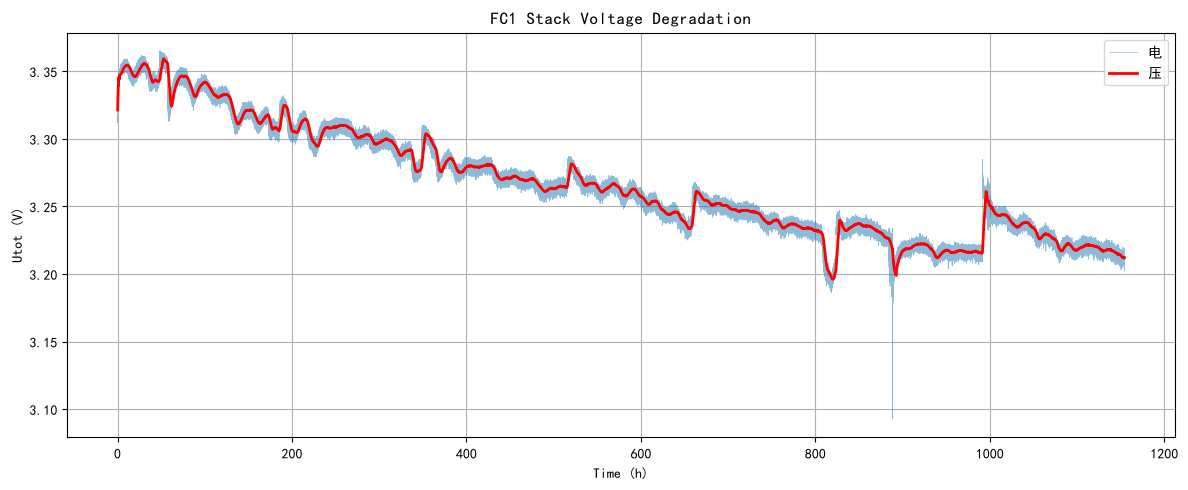


电压统计：
count    143847.000000
mean          3.270040
std           0.042673
min           3.093000
25%           3.234000
50%           3.263000
75%           3.305000
max           3.365000
Name: Utot (V), dtype: float64


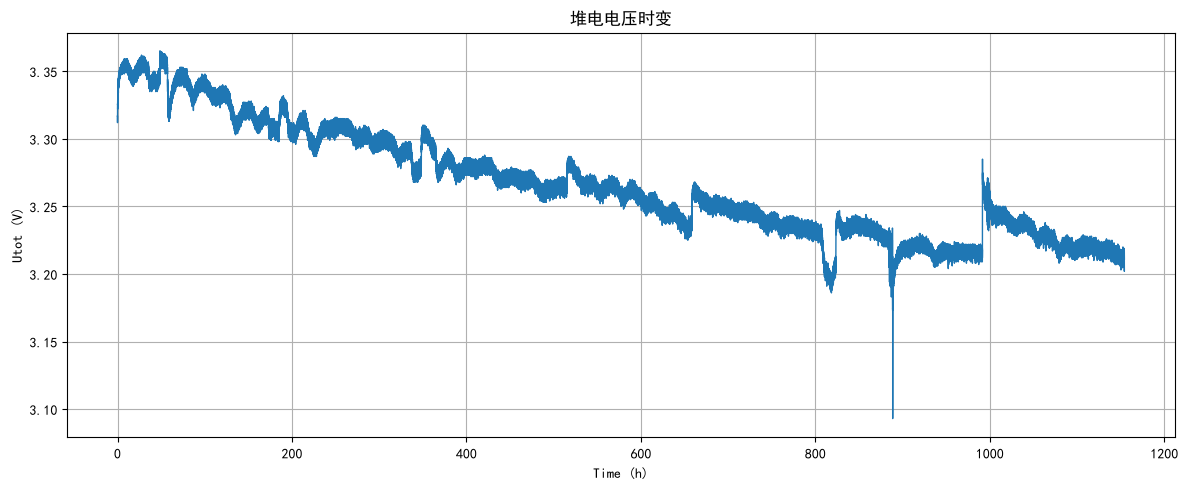

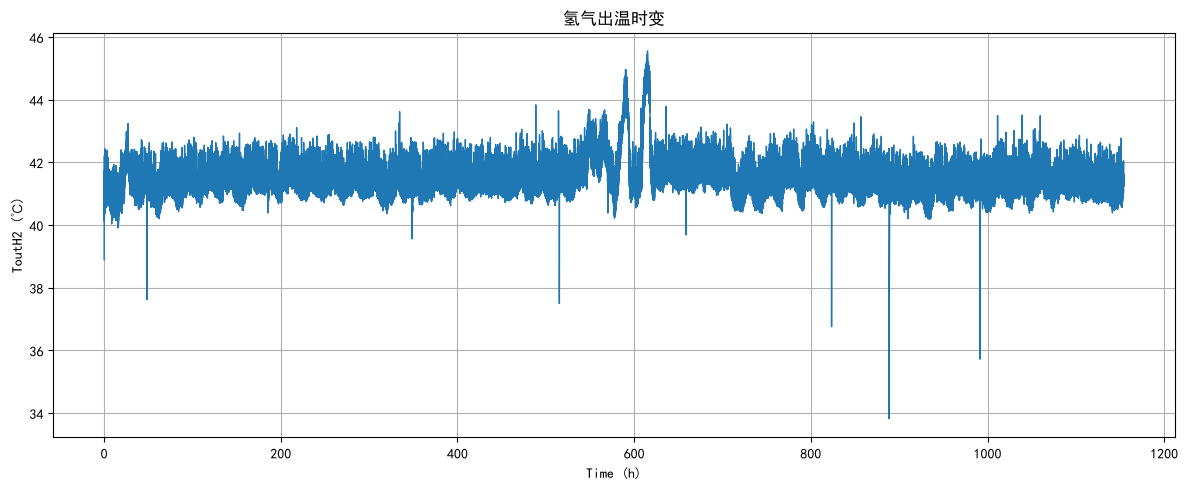

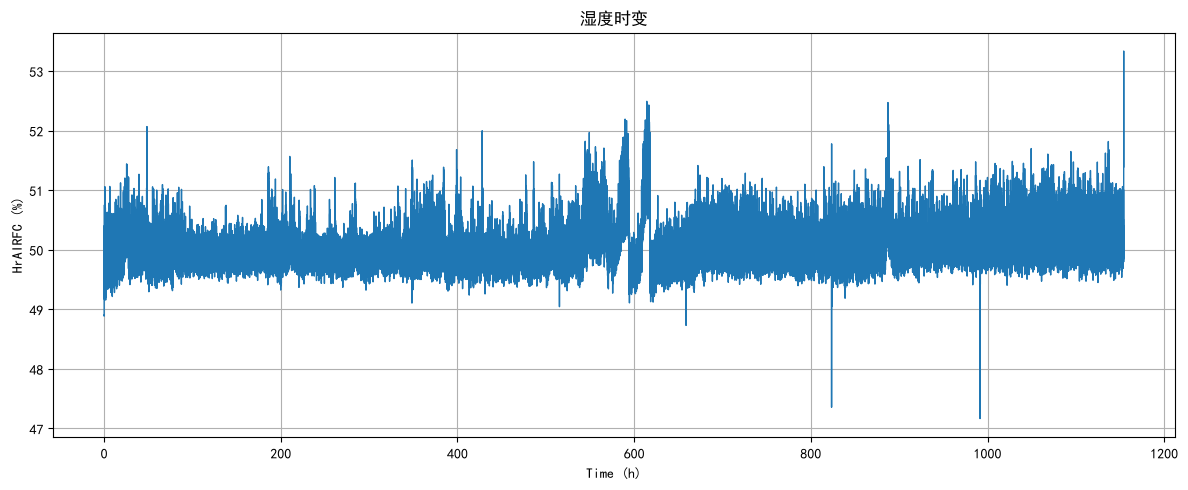

初始电压 = 3.31699
最终电压 = 3.21273
总衰减 = 0.10426000000000002 V
衰减百分比 = 3.1432111643387537 %

95%阈值 = 3.1511405 V
整段数据中电压从未降到 95% 以下
最低滚动平均 = 3.196116


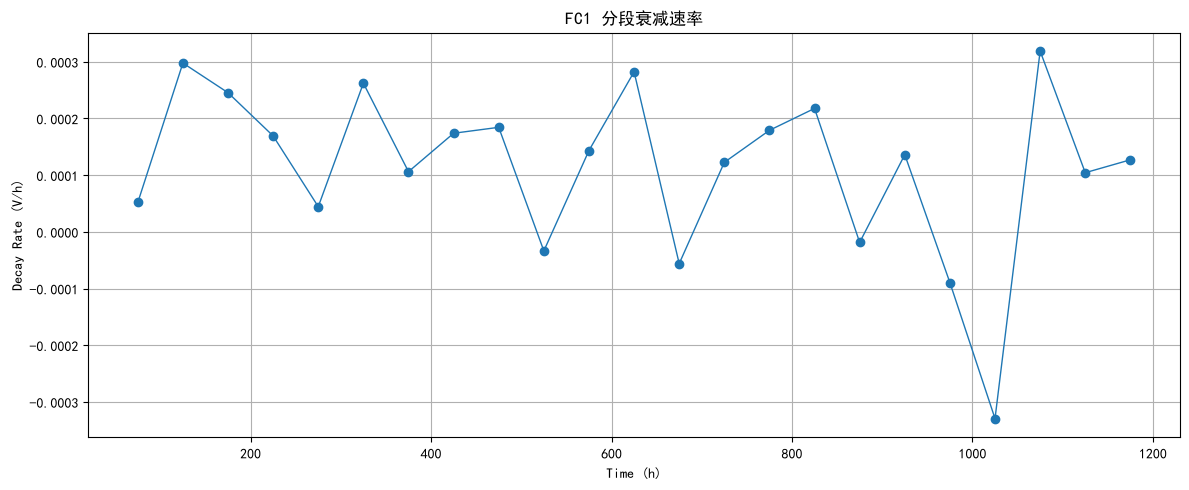

时间段中点 (h) | 衰减速率 (V/h)
    75.0      | 0.000052
   125.0      | 0.000298
   175.0      | 0.000245
   225.0      | 0.000169
   275.0      | 0.000044
   325.0      | 0.000262
   375.0      | 0.000106
   425.0      | 0.000174
   475.0      | 0.000184
   525.0      | -0.000034
   575.0      | 0.000143
   625.0      | 0.000282
   675.0      | -0.000056
   725.0      | 0.000123
   775.0      | 0.000179
   825.0      | 0.000218
   875.0      | -0.000019
   925.0      | 0.000136
   975.0      | -0.000089
  1025.0      | -0.000329
  1075.0      | 0.000319
  1125.0      | 0.000104
  1175.0      | 0.000127


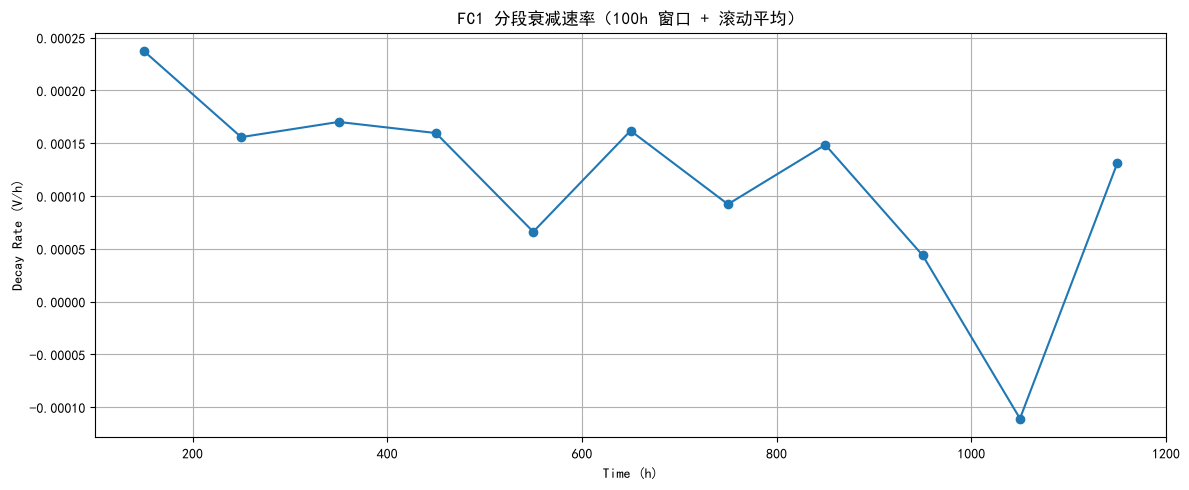

时间段中点 (h) | 衰减速率 (V/h)
   150.0      | 0.000237
   250.0      | 0.000156
   350.0      | 0.000170
   450.0      | 0.000160
   550.0      | 0.000066
   650.0      | 0.000162
   750.0      | 0.000092
   850.0      | 0.000148
   950.0      | 0.000044
  1050.0      | -0.000111
  1150.0      | 0.000131


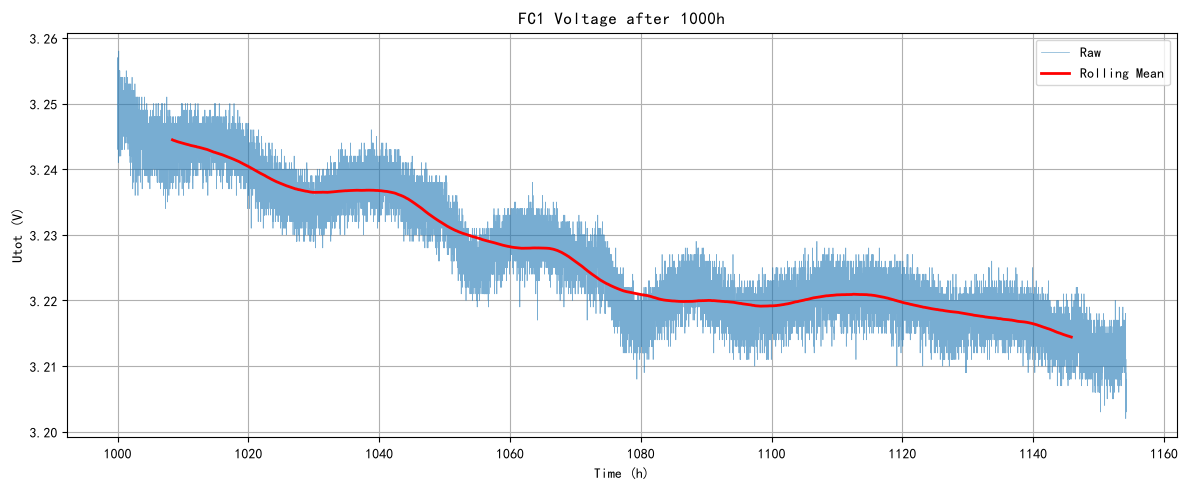

1000h 后数据点数： 18382
1000h 后电压范围： 3.202 到 3.258


In [1]:
#%matplotlib inline#接入matplotlib
import numpy as np  #引入numpy，命名为np，用来做线性代数，数组操作，随机数，向量化运算
import pandas as pd  #引入pandas，命名为pd，它用来读表格、数据，在python里干excel表格的事（统计，筛查，计算，处理）
import matplotlib.pyplot as plt#引入matplotlib.pylot，命名为plt，它用来画图
import glob  #是“找文件”的函数。
import os  #os用来管理文件和文件夹路径
#提取工具（）

plt.rcParams['font.sans-serif'] = ['SimHei']#兼容中文
plt.rcParams['axes.unicode_minus'] = False#兼容中文

folder = r'C:\Users\YOGA\Desktop\电池ai分析\IEEE2014DataChallengeData\IEEE 2014 Data Challenge Data\FC1_Without_Ripples\csv 1'#确定文件路径
#file_path = r'C:\Users\YOGA\Desktop\电池ai分析\IEEE2014DataChallengeData\IEEE 2014 Data Challenge Data\FC1_Without_Ripples\csv 1\FC1_Ageing_part1.csv'#确定文件路径

files = glob.glob(os.path.join(folder, '*.csv'))#glob.glob表示找路径，如何路径返还给py
print("找到的文件：")#os.path.join(folder, '*.csv')把两段文字拼成一个完整的路径，让三文档都能被找到
for f in files:#for f in files：循环，每次拿出来一个长路径，叫它 f。
    print("  ", os.path.basename(f))#os.path.basename(f)：“提取基础名字”。它不管前面的长串路径，只把最后面的 part1.csv 抠出来。

dfs = []   #dfs = []：建一个空列表，准备装三个 DataFrame。
for f in files:#for f in files：意思是：“对于 files 里面的每一个东西，我都挨个拿出来，取个外号叫 f，然后执行下面的操作。” 一直循环到列表里没有东西为止。
    temp = pd.read_csv(f, encoding='latin1')#encoding='latin1'万能兼容大法
    dfs.append(temp)#.append() 就是“插队到最后一个”。
    #循环每次读一个文件，存到 temp，然后 dfs.append(temp) 把 temp 塞进列表。
    #循环结束后，dfs 是一个包含三个 DataFrame 的列表。
    #在 Python 里，循环结束后，f 通常会保留最后一次的值

    print(f"读入 {os.path.basename(f)}，形状 {temp.shape}")#os.path.join(folder, '*.csv') 把文件夹路径和 '*.csv' 拼成完整的路径模式。

df = pd.concat(dfs, ignore_index=True)#拼接表格，concat是竖着拼起来
#ignore_index=True：拼接后重新编号，不保留原来的 index。如果不写，每个表的 index 都是 0,1,2,...，拼起来会重复。

# 可能需要的关键改动 1：read_excel；2：header=1 跳过中文标题行（跳过第一行）
#df = pd.read_csv(file_path, encoding='latin1')#读文件

print("每列缺失值数量：")
print(df.isnull().sum())#df.isnull().sum()#数每一列有多少个空值。如果某列空值很多，后面要么删掉这一列，要么填充。如果空值很少（比如个位数），可以直接删掉那几行。全0会出int64，表整数。
#.isnull() 是找空缺的意思，有数据的地方标 False，空缺的地方标 True。（注意，缺的地方是Ture，不是False）
#可以把.isnull()理解为“有空缺吗？回答（是或否）”

print("数据形状：", df.shape)#告诉行列式
print(df.dtypes)#告诉我们表内数据类型（防止数字表里面混进去汉字），dtypes是data types数据类型，一般都是float64小数

df = df.sort_values('Time (h)').reset_index(drop=True)#各行编号就是 index；reset_index可以删去旧有index的映射；sort_values('Time (h)')表示用时间重排序，这样的话，就可以让index和时间顺序一一对应。
print("\n排序后前 5 行：")#\n表示换行
print(df[['Time (h)', 'Utot (V)', 'ToutH2 (°C)', 'HrAIRFC (%)']].head())#打印表格内的这几列，.head(n)表示前n行，如果空着，默认前五行。。.tail()，显示最后 5 行。

time_diff = df['Time (h)'].diff()#.diff()：对相邻两行做减法，算“当前行减去上一行”。
print("\n时间间隔统计：")
print(time_diff.describe())
#describe() 对这个差值序列做描述性统计：count：有多少个非空差值； mean：平均时间间隔；std：时间间隔的标准差；  min：最小间隔；  25%、50%、75%：四分位数；  max：最大间隔。。。。
# 这里算出来的数全是.diff里面的，要看原数据就用df['Time (h)'].describe()

#min出0了，表示数据时间重合，会影响后面的建模，处理方式有两种：删掉重复时间戳的行：
#df = df.drop_duplicates(subset='Time (h)', keep='first') #   或者接受它，因为 0 间隔的比例很小
#duplicated() 是标记;drop_duplicates 是为了“真的删掉”
#mean 比 median（50%） 小很多。 中位数高于均值。均值被拉低，说明有一些比正常间隔小得多的值。这进一步证实了“存在重复时间戳或间隔不均”的判断。后面做滑动窗口之前，可能需要先处理这些短间隔，也就是务必要把零间隔的行去掉。

# 看时间列有多少重复值
print("重复时间行数：", df['Time (h)'].duplicated().sum())

# 看具体哪些时间是重复的（前 10 个）
dup_times = df[df['Time (h)'].duplicated(keep=False)]
#duplicated() 就是标记，df[[...]] 才是筛选。(删去False，留下Ture)
#duplicated(keep=False) 是为了“看看到底哪些重复”，用 drop_duplicates 是为了“真的删掉”。两步分开做，逻辑很清晰。
print("\n重复时间的前 10 行：")
print(dup_times[['Time (h)', 'Utot (V)']].head(10))

#如果重复行不多（比如几十行），直接删掉：
df = df.drop_duplicates(subset='Time (h)', keep='first').reset_index(drop=True)#subset 意思是“子集”
#subset='Time (h)'：以时间作判据
print("去重后数据形状：", df.shape)
#keep='first' 表示保留第一次出现的那行，删掉后面重复的。reset_index(drop=True) 重新编号。

plt.figure(figsize=(12, 5))

# 原始电压                                  （细线         半透明）
plt.plot(df['Time (h)'], df['Utot (V)'], linewidth=0.5, alpha=0.5, label='Raw')

# 滚动平均（粗线，窗口 500 个点，约 4 小时）
df['Utot_rolling'] = df['Utot (V)'].rolling(window=500).mean()
plt.plot(df['Time (h)'], df['Utot_rolling'], linewidth=2, color='red', label='Rolling Mean (500)')
# rolling(window=500).mean() 取每 500 个点的平均值，把短期波动抹掉，露出长期衰减趋势。红色的平滑线才是你们真正要预测的“耐久性曲线”。
plt.xlabel('Time (h)')
plt.ylabel('Utot (V)')
plt.title('FC1 Stack Voltage Degradation')
plt.legend("电压平滑线")
plt.grid(True)
plt.tight_layout()
plt.show()
#滚动平均的作用：原始电压有无数个小的峰谷波动（测量噪声、瞬时工况变化）。

print("\n电压统计：")
print(df['Utot (V)'].describe())#同上
#衰减幅度：从 3.365 V 掉到 3.253 V，总共衰减了 0.112 V，约 3.3%。这就是要预测的“耐久性衰减”。1000 小时衰减 3.3%，这个幅度不算大，说明 FC1 的工况相对温和，适合先跑通方法。

#画图
plt.figure(figsize=(12, 5))#figsize 是 figure size（图片尺寸） 的缩写。(12, 5) 表示宽12、高5。随意调
plt.plot(df['Time (h)'], df['Utot (V)'], linewidth=1)
plt.xlabel('Time (h)')
plt.ylabel('Utot (V)')
plt.title('堆电电压时变')
plt.grid(True)#（）默认打开，（True）开，（false）关，不可以用on和off。
plt.tight_layout()#tight_layout 是自动调整边距，把所有元素都完整显示出来。
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(df['Time (h)'], df['ToutH2 (°C)'], linewidth=1)
plt.xlabel('Time (h)')
plt.ylabel('ToutH2 (℃)')
plt.title('氢气出温时变')
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(df['Time (h)'], df['HrAIRFC (%)'], linewidth=1)
plt.xlabel('Time (h)')
plt.ylabel('HrAIRFC (%)')
plt.title('湿度时变')
plt.grid(True)
plt.tight_layout()
plt.show()


V_initial = df['Utot (V)'].iloc[:100].mean()#.iloc[:100]表示取前 100 个点的平均
print("初始电压 =", V_initial)#.iloc[]是取的意思

V_final = df['Utot (V)'].iloc[-100:].mean()#.iloc[-100:]取最后 100 个点的平均
print("最终电压 =", V_final)

V_drop = V_initial - V_final
print("总衰减 =", V_drop, "V")
print("衰减百分比 =", V_drop / V_initial * 100, "%")

threshold = V_initial * 0.95
print("\n95%阈值 =", threshold, "V")

df['Utot_rolling'] = df['Utot (V)'].rolling(window=500).mean()#这里画出来就没有半透乱刺了

below = df[df['Utot_rolling'] < threshold]
if len(below) > 0:#len() 是 length 的缩写，就是“数长度/数个数”。
    # len(below) 就是数一数 below 这个表格里有几行数据。> 0 就是问：“里面有数据吗？”
    t_95 = below['Time (h)'].iloc[0]
    print("首次低于 95% 的时间：", t_95, "h")
else:
    print("整段数据中电压从未降到 95% 以下")
    print("最低滚动平均 =", df['Utot_rolling'].min())

# 分段算衰减速率：每 50 小时一段
import numpy as np

# 生成分段边界
t_start = df['Time (h)'].min()
t_end = df['Time (h)'].max()
bin_edges = np.arange(t_start, t_end + 50, 50)   #np.arange(start, stop, step)

bin_centers = []#这里仅仅只是创造了一个表格，没有进行定义、赋值
bin_voltages = []

for i in range(len(bin_edges) - 1):
    #这段for就像是“切蛋糕”。bin_edges 就是切蛋糕的“刀口”，0, 50, 100, 150...遇到就切一刀
    #for i in range(len(bin_edges) - 1)：因为 3 个刀口只能切出 2 块蛋糕，所以循环次数要减 1。
    left = bin_edges[i]#这里[n]表示编号“n”不是i个小时
    right = bin_edges[i + 1]
    #Python 的列表，有两套语言，一个是“抽屉编号”，一个是“抽屉里的东西”。
    segment = df[(df['Time (h)'] >= left) & (df['Time (h)'] < right)]
    #segment = df[(... >= left) & (... < right)]：用切出来的范围，去原表里把 0-50 小时的数据全抠出来。
    if len(segment) > 0:
        bin_centers.append((left + right) / 2)
        bin_voltages.append(segment['Utot (V)'].mean())
        # 第 2 步：append往列表里塞数据，列表变成 [25.0, 75.0, 125.0, ...]

# 算相邻两段的电压差，除以时间差，得到衰减速率
bin_centers = np.array(bin_centers)# 第 3 步：把列表转成 numpy 数组，覆盖原来的变量名
bin_voltages = np.array(bin_voltages)
#执行之后，bin_centers和bin_voltages 不再是一个 list，而是一个 numpy array。 原来的列表被丢弃了。
#为什么要转？ 因为后面要写 bin_centers[1:]（切片）和 np.diff(bin_voltages)。numpy array 支持这些操作，list 也支持切片，但 np.diff 需要 numpy array。统一转成 array 更省心。
#a = [1, 2, 3]这是 list      b = np.array([1, 2, 3])这是 numpy array
#在你们项目里，凡是需要做数学运算的序列，都建议转成 numpy array。

decay_rate = -np.diff(bin_voltages) / 50   # 加负号，让正值表示“衰减速率”

# 画图
plt.figure(figsize=(12, 5))
plt.plot(bin_centers[1:], decay_rate, marker='o', linewidth=1)
plt.xlabel('Time (h)')
plt.ylabel('Decay Rate (V/h)')
plt.title('FC1 分段衰减速率')
plt.grid(True)
plt.tight_layout()
plt.show()

# 打印数值
print("时间段中点 (h) | 衰减速率 (V/h)")
for t, r in zip(bin_centers[1:], decay_rate):
    print(f"{t:8.1f}      | {r:.6f}")
#zip 是“拉链”的意思。在 Python 里，它的作用就是“左右手同时拿牌，凑成一对”。
#zip(bin_centers[1:], decay_rate) 就是把这两个列表里的元素，按顺序一对一打包起来。
#[1:] 叫切片，意思是“从第 2 个元素开始，一直取到最后”（因为 Python 是从 0 开始数数的，1 就是第二个）
#.iloc[:100]表示前一百个，.iloc[-100:]表示后一百个
#f"{t:8.1f} | {r:.6f}"专门用来对齐排版用的。
# {t:8.1f}：把时间 t 打印出来占 8 个字符的宽度，保留 1 位小数。
# {r:.6f}：把速率 r 打印出来，保留 6 位小数。
# 中间的 | 就是纯粹画一条竖线，把两边隔开。


import numpy as np

# 先算滚动平均（窗口 2000 个点，约 17 小时）
df['Utot_smooth'] = df['Utot (V)'].rolling(window=2000, center=True).mean()

# 用 100 小时分段
t_start = df['Time (h)'].min()
t_end = df['Time (h)'].max()
bin_edges = np.arange(t_start, t_end + 100, 100)

bin_centers = []
bin_voltages = []

for i in range(len(bin_edges) - 1):
    left = bin_edges[i]
    right = bin_edges[i + 1]
    segment = df[(df['Time (h)'] >= left) & (df['Time (h)'] < right)]
    if len(segment) > 0:
        bin_centers.append((left + right) / 2)
        bin_voltages.append(segment['Utot_smooth'].mean())

bin_centers = np.array(bin_centers)
bin_voltages = np.array(bin_voltages)

decay_rate = -np.diff(bin_voltages) / 100

plt.figure(figsize=(12, 5))
plt.plot(bin_centers[1:], decay_rate, marker='o', linewidth=1.5)
plt.xlabel('Time (h)')
plt.ylabel('Decay Rate (V/h)')
plt.title('FC1 分段衰减速率（100h 窗口 + 滚动平均）')
plt.grid(True)
plt.tight_layout()
plt.show()

print("时间段中点 (h) | 衰减速率 (V/h)")
for t, r in zip(bin_centers[1:], decay_rate):
    print(f"{t:8.1f}      | {r:.6f}")

#df.to_csv(r'...\csv 1\FC1_full.csv', index=False, encoding='utf-8-sig')
#把 df 存成 FC1_full.csv，以后不用重新拼。存完之后，后面所有代码直接从 FC1_full.csv 读，速度更快、更省事。

# 只看 1000 小时之后的数据
tail = df[df['Time (h)'] > 1000]

plt.figure(figsize=(12, 5))
plt.plot(tail['Time (h)'], tail['Utot (V)'], linewidth=0.5, alpha=0.6, label='Raw')
tail_smooth = tail['Utot (V)'].rolling(window=2000, center=True).mean()
plt.plot(tail['Time (h)'], tail_smooth, linewidth=2, color='red', label='Rolling Mean')
plt.xlabel('Time (h)')
plt.ylabel('Utot (V)')
plt.title('FC1 Voltage after 1000h')
plt.legend()
plt.grid(True)
plt.tight_layout()

# 保存到桌面，格式 png，分辨率 300 dpi
#plt.savefig(r'C:\Users\YOGA\Desktop\名字', dpi=300, bbox_inches='tight')
#批量保存：如果你有多张图要存，每张图前面加一个 plt.figure()，画完就 savefig + show，互不干扰。

plt.show()

print("1000h 后数据点数：", len(tail))
print("1000h 后电压范围：", tail['Utot (V)'].min(), "到", tail['Utot (V)'].max())

In [9]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# ================= 1. 读入 FC2 数据 =================
# 请换成你 FC2 实际的文件路径
file_path = r'C:\Users\YOGA\Desktop\电池ai分析\IEEE2014DataChallengeData\IEEE 2014 Data Challenge Data\FC2\FC2.v1.csv'

# 编码问题：如果报错，把 encoding 换成 'gbk' 或 'latin1'
df = pd.read_csv(file_path, encoding='latin1')

# 【关键步骤】先看看列名对不对！
print("FC2 数据包含的列名：")
print(df.columns.tolist())

# ================= 2. 提取特征并进行 8:2 切分 =================
# 确保这里的列名和上面打印出来的完全一致
features = ['ï»¿Time (h)', 'Utot (V)', 'ToutH2 (Â°C)', 'HrAIRFC (%)']
data = df[features].values

# 计算切分点（80% 的位置）
split_idx = int(len(data) * 0.8)

# 前 80% 作为训练集，后 20% 作为测试集
train_data = data[:split_idx]
test_data = data[split_idx:]

print(f"\n数据总行数: {len(data)}")
print(f"训练集 (前80%) 行数: {len(train_data)}")
print(f"测试集 (后20%) 行数: {len(test_data)}")

# ================= 3. 严格防泄漏归一化 =================
scaler = MinMaxScaler(feature_range=(0, 1))
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train_data)
test_scaled = scaler.transform(test_data)
train_df_scaled = pd.DataFrame(train_scaled, columns=features)
test_df_scaled = pd.DataFrame(test_scaled, columns=features)

print("\n✅ 归一化完成！train_scaled 和 test_scaled 已经准备好。")

train_df_scaled.to_csv(r'C:\Users\YOGA\Desktop\FC2测试集.csv', index=False)
test_df_scaled.to_csv(r'C:\Users\YOGA\Desktop\FC2训练集.csv', index=False)

print("💾 保存成功！去桌面看看 FC2_train_80.csv 和 FC2_test_20.csv 吧。")

FC2 数据包含的列名：
['ï»¿Time (h)', 'U1 (V)', 'U2 (V)', 'U3 (V)', 'U4 (V)', 'U5 (V)', 'Utot (V)', 'J (A/cmÂ²)', 'I (A)', 'TinH2 (Â°C)', 'ToutH2 (Â°C)', 'TinAIR (Â°C)', 'ToutAIR (Â°C)', 'TinWAT (Â°C)', 'ToutWAT (Â°C)', 'PinAIR (mbara)', 'PoutAIR (mbara)', 'PoutH2 (mbara)', 'PinH2 (mbara)', 'DinH2 (l/mn)', 'DoutH2 (l/mn)', 'DinAIR (l/mn)', 'DoutAIR (l/mn)', 'DWAT (l/mn)', 'HrAIRFC (%)', 'Unnamed: 25']

数据总行数: 127350
训练集 (前80%) 行数: 101880
测试集 (后20%) 行数: 25470

✅ 归一化完成！train_scaled 和 test_scaled 已经准备好。
💾 保存成功！去桌面看看 FC2_train_80.csv 和 FC2_test_20.csv 吧。
